## Import thư viện và Load dữ liệu Train

In [4]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Định vị thư mục gốc và import module
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.lab02_utils.stats import perform_adf_test

# 2. Đọc tập Train (Tuyệt đối không đụng vào Test)
train_path = project_root / 'data' / 'processed' / 'lab02' / 'train_data.csv'
train_df = pd.read_csv(train_path, parse_dates=['Month'], index_col='Month')

# Cấu hình biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## Lấy sai phân bậc 1 ($d=1$) cho ARIMA
*Sai phân bậc 1 (First Difference) giúp loại bỏ Xu hướng (Trend) bằng cách lấy giá trị tháng hiện tại trừ đi tháng liền trước.*

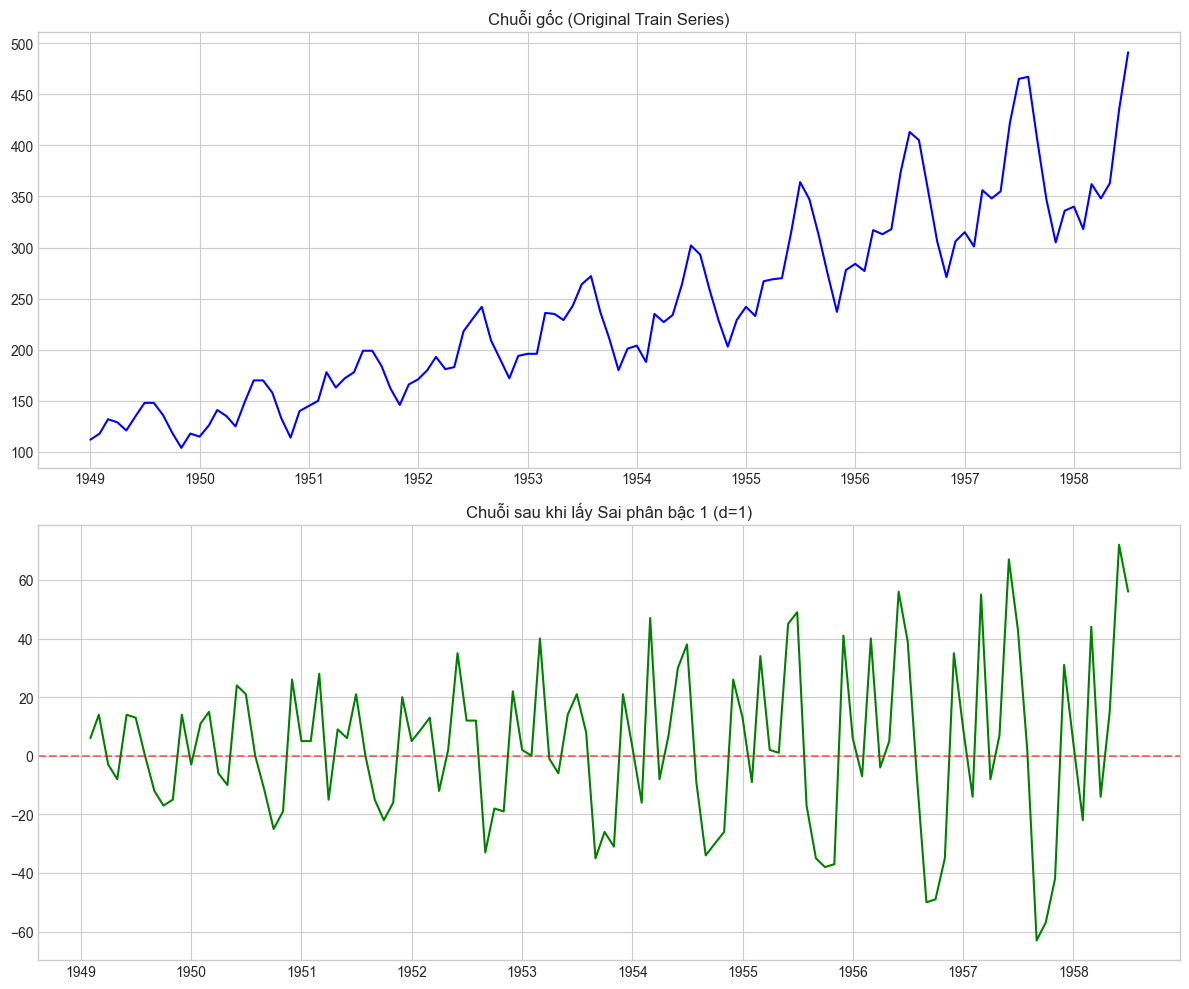

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 (D=1) ==========
Số quan sát đầu vào : 114
Số độ trễ (Lags)    : 13
Số quan sát sử dụng : 100
ADF Statistic       : -2.5396
p-value             : 0.1061

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4975
   > 5%: -2.8909
   > 10%: -2.5824

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.1061 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!



d:\vscode\Lab_TimeSeries\src\lab02_utils\stats.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')


0.10612609999673461

In [5]:
# Lấy sai phân bậc 1 (d=1)
train_df['Diff_1'] = train_df['Passengers'].diff(periods=1)

# Vẽ đồ thị so sánh Chuỗi gốc và Chuỗi sau khi sai phân bậc 1
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(train_df.index, train_df['Passengers'], color='blue')
axes[0].set_title('Chuỗi gốc (Original Train Series)')

axes[1].plot(train_df.index, train_df['Diff_1'], color='green')
axes[1].set_title('Chuỗi sau khi lấy Sai phân bậc 1 (d=1)')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5) # Đường 0 tham chiếu

plt.tight_layout()
plt.show()

# Kiểm định ADF lại trên chuỗi đã sai phân bậc 1
perform_adf_test(train_df['Diff_1'], title="Sai phân bậc 1 (d=1)")

## Lấy sai phân mùa vụ ($D=1, s=12$) cho SARIMA
*Sau khi lấy sai phân bậc 1, đồ thị Diff_1 vẫn có sự dao động mạnh theo từng năm (chu kỳ). Vì vậy, ta tiếp tục lấy sai phân bậc 1 của mùa vụ (Seasonal Difference) với chu kỳ 12 tháng.*

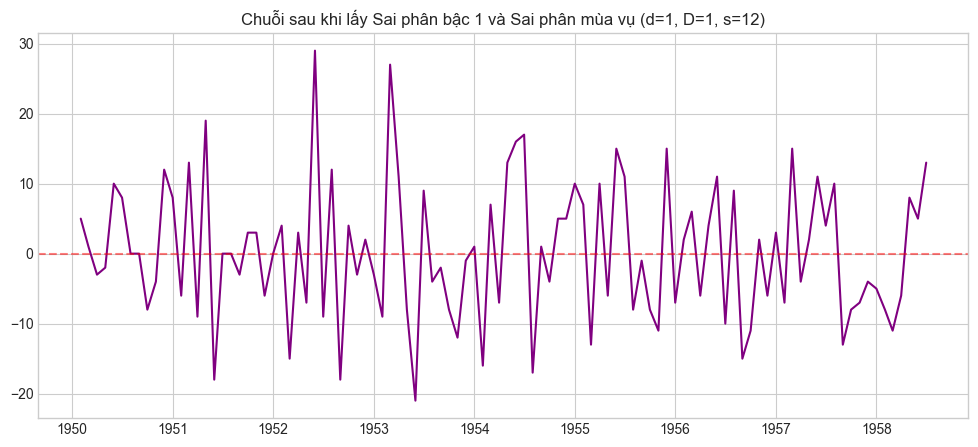

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 + MÙA VỤ (D=1, D=1, S=12) ==========
Số quan sát đầu vào : 102
Số độ trễ (Lags)    : 0
Số quan sát sử dụng : 101
ADF Statistic       : -12.1763
p-value             : 0.0000

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4968
   > 5%: -2.8906
   > 10%: -2.5823

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.0000 < 0.05: Đủ cơ sở bác bỏ H0.
=> CHUỖI ĐÃ DỪNG (Stationary).



d:\vscode\Lab_TimeSeries\src\lab02_utils\stats.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')


1.3839808857959483e-22

In [6]:
# Lấy sai phân mùa vụ (D=1, chu kỳ s=12) TRÊN NỀN chuỗi đã sai phân bậc 1
train_df['Diff_1_12'] = train_df['Diff_1'].diff(periods=12)

# Vẽ đồ thị Chuỗi sau khi lấy sai phân mùa vụ
plt.figure(figsize=(12, 5))
plt.plot(train_df.index, train_df['Diff_1_12'], color='purple')
plt.title('Chuỗi sau khi lấy Sai phân bậc 1 và Sai phân mùa vụ (d=1, D=1, s=12)')
plt.axhline(0, color='red', linestyle='--', alpha=0.5)
plt.show()

# Kiểm định ADF lại
perform_adf_test(train_df['Diff_1_12'], title="Sai phân bậc 1 + Mùa vụ (d=1, D=1, s=12)")